# Regrouping particles according to northern threshold boundary

- Particles are seeded randomly at the ARP, because the pathways are not yet suitable for clustering, we want to group them in a way that facilitates the clusters.
- Try regroupping the particles and resetting the time-stamps at 2N, 2.5N,..., 12N (retroflection)
- Total area is 79 x 29 cells of about 1.04 deg lon x 1.26 deg lat over
97.0W-14.7W, 4.4S-32.0N

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

In [2]:
path0 = '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/'


In [3]:
ds_traj = xr.open_dataset(path0+'Parcels_run_67891_2006-01-24 00:00:00.zarr').compute()
ds_traj

<xarray.Dataset> Size: 419MB
Dimensions:     (trajectory: 10105, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 81kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 60MB 0.8943 0.9149 ... 18.53 18.53
    lon         (trajectory, obs) float64 60MB -49.76 -49.76 ... -66.36 -66.33
    ndry        (trajectory, obs) float64 60MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    nrefine     (trajectory, obs) float64 60MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    sal         (trajectory, obs) float32 30MB 8.542 7.697 7.719 ... 36.0 35.93
    temp        (trajectory, obs) float32 30MB 28.46 28.2 28.17 ... 28.26 28.33
    time        (trajectory, obs) datetime64[ns] 60MB 2006-01-24 ... 2006-07-...
    z           (trajectory, obs) float64 60MB 3.472 3.202 2.952 ... 38.81 36.44
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [4]:
# rp = np.random.choice(ds_traj.trajectory.size, size=100, replace=False)
# rp

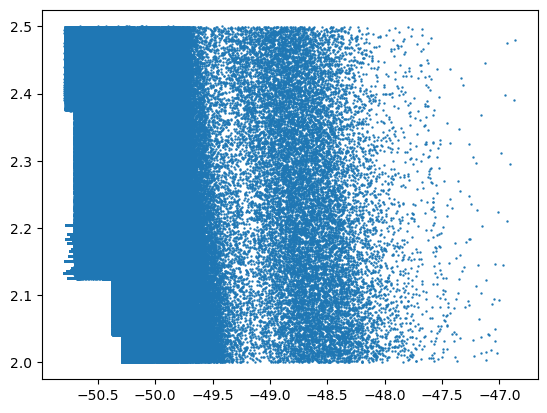

In [8]:
ds_filt = ds_traj.where((ds_traj.lat<2.5) & (ds_traj.lat>=2))
ds_filt
plt.scatter(ds_filt.lon, ds_filt.lat,s=0.5)

In [9]:
ds_filt

<xarray.Dataset> Size: 419MB
Dimensions:     (trajectory: 10105, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 81kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 60MB nan nan nan nan ... nan nan nan
    lon         (trajectory, obs) float64 60MB nan nan nan nan ... nan nan nan
    ndry        (trajectory, obs) float64 60MB nan nan nan nan ... nan nan nan
    nrefine     (trajectory, obs) float64 60MB nan nan nan nan ... nan nan nan
    sal         (trajectory, obs) float32 30MB nan nan nan nan ... nan nan nan
    temp        (trajectory, obs) float32 30MB nan nan nan nan ... nan nan nan
    time        (trajectory, obs) datetime64[ns] 60MB NaT NaT NaT ... NaT NaT
    z           (trajectory, obs) float64 60MB nan nan nan nan ... nan nan nan
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [14]:
lat0 = 2.5                                    # threshold latitude

sub = ds_traj                                 # all particles

# first step where the particle goes from south of lat0 to north of it
cross   = (sub.lat.shift(obs=1) < lat0) & (sub.lat >= lat0)
crossed = cross.any('obs')                    # False if it never reaches lat0
idx     = cross.argmax('obs')                 # obs index of first crossing

t0 = sub.time.isel(obs=idx)                   # crossing time per particle
sub['ntime'] = sub.time - t0                  # 0 at crossing, negative before
sub = sub.where(crossed, drop=True)           # drop particles that never cross

print(f"{int(crossed.sum())} of {crossed.size} particles cross {lat0}N")

10068 of 10105 particles cross 2.5N


Text(0, 0.5, 'lat')

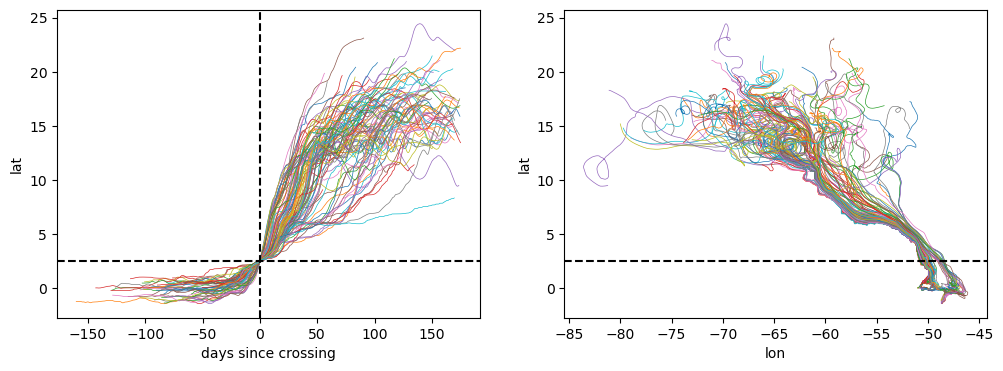

In [15]:
# check: plot 100 random crossing particles
some  = sub.isel(trajectory=np.random.choice(sub.trajectory.size, 100, replace=False))
ndays = some.ntime / np.timedelta64(1, 'D')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ndays.T, some.lat.T, lw=0.5)
ax[0].axhline(lat0, c='k', ls='--'); ax[0].axvline(0, c='k', ls='--')
ax[0].set_xlabel('days since crossing'); ax[0].set_ylabel('lat')
ax[1].plot(some.lon.T, some.lat.T, lw=0.5)
ax[1].axhline(lat0, c='k', ls='--')
ax[1].set_xlabel('lon'); ax[1].set_ylabel('lat')

In [16]:
sub

<xarray.Dataset> Size: 477MB
Dimensions:     (trajectory: 10068, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 81kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 60MB 0.8943 0.9149 ... 18.53 18.53
    lon         (trajectory, obs) float64 60MB -49.76 -49.76 ... -66.36 -66.33
    ndry        (trajectory, obs) float64 60MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    nrefine     (trajectory, obs) float64 60MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    sal         (trajectory, obs) float32 30MB 8.542 7.697 7.719 ... 36.0 35.93
    temp        (trajectory, obs) float32 30MB 28.46 28.2 28.17 ... 28.26 28.33
    time        (trajectory, obs) datetime64[ns] 60MB 2006-01-24 ... 2006-07-...
    z           (trajectory, obs) float64 60MB 3.472 3.202 2.952 ... 38.81 36.44
    ntime       (trajectory, obs) timedelta64[ns] 60MB -11 days +06:00:00 ......
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [10]:
lat_min=ds_traj.lat.min().data[()]
lon_min=ds_traj.lon.min().data[()]

lat_max=ds_traj.lat.max().data[()]
lon_max=ds_traj.lon.max().data[()]

lat_bins = np.linspace(lat_min, lat_max, 30)
lon_bins = np.linspace(lon_min, lon_max, 80)

In [48]:
def calc_hist(d):
    """template's histogram: lon/lat counts per obs step"""
    return xhist(d.lon, d.lat, bins=[lon_bins, lat_bins],
                 dim=["trajectory"], bin_dim_suffix="")

In [17]:
from xhistogram.xarray import histogram as xhist

lat0 = 2.5
cross   = (ds_traj.lat.shift(obs=1) < lat0) & (ds_traj.lat >= lat0)
crossed = cross.any('obs')            # 37 particles never cross -> dropped (NaN)
idx     = cross.argmax('obs')         # crossing step of each particle

# shift each track so step 0 = its crossing
nobs = ds_traj.obs.size
step = xr.DataArray(np.arange(nobs), dims='step')
j  = idx + step
ok = (j < nobs) & crossed
al = ds_traj[['lon','lat']].isel(obs=j.where(ok, 0)).where(ok).drop_vars('obs')

h = xhist(al.lon, al.lat, bins=[lon_bins, lat_bins], dim=['trajectory'], bin_dim_suffix='')
# h.isel(step=0)   -> where particles are when they cross 2.5N
# h.isel(step=40)  -> 10 days after crossing (6-hourly output, 4 steps/day)


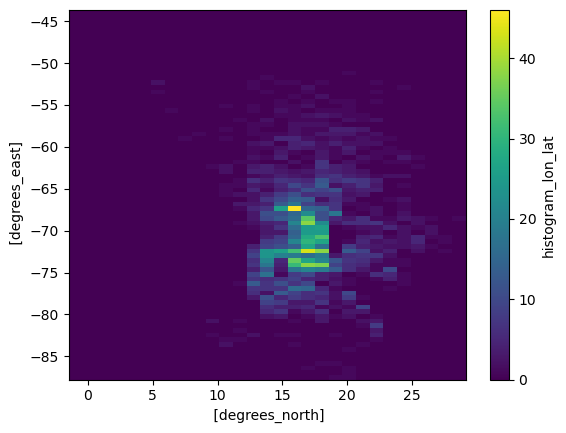

In [28]:
h.isel(step=160*4).plot()